# 📚 Опис Використаних Бібліотек

---

### 1. **NumPy**
- Для роботи з багатовимірними масивами та виконання математичних операцій.

### 2. **scikit-learn** (sklearn)
- Для машинного навчання: класифікація, регресія, кластеризація, оцінка моделей.

### 3. **Matplotlib**
- Для візуалізації даних: створення графіків, гістограм, діаграм.

### 4. **Pandas**
- Для роботи з таблицями: обробка, фільтрація, групування даних.

### 5. **Seaborn**
- Для покращеної візуалізації: стилізовані графіки та статистичні діаграми.

---

Ці бібліотеки допоможуть нам ефективно працювати з даними та будувати моделі машинного навчання.

In [7]:
#@title Необхідні імпорти

import numpy as np
from sklearn.linear_model import SGDRegressor, LinearRegression
from sklearn.datasets import make_regression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib as mpl
import seaborn as sns
from IPython.display import HTML
import warnings
from matplotlib.animation import FuncAnimation
import numpy as np
import random

random.seed(42)
np.random.seed(42)
warnings.filterwarnings('ignore')

# 📊 Лінійна Регресія

Лінійна регресія — це метод машинного навчання з вчителем, який використовується для прогнозування числових значень залежної змінної на основі значень однієї або кількох незалежних змінних. Цей метод передбачає лінійний зв'язок між змінними.

### 🔑 Основні типи лінійної регресії:
- **Проста лінійна регресія**: прогнозує значення залежної змінної на основі однієї незалежної змінної.
- **Множинна лінійна регресія**: прогнозує значення залежної змінної на основі кількох незалежних змінних.

### 🌍 Застосування лінійної регресії:
- **💰 Економіка**: прогнозування попиту, цін, курсів валют.
- **📉 Фінанси**: оцінка кредитних ризиків, прогнозування цін на акції.
- **📈 Маркетинг**: аналіз ефективності рекламних кампаній, прогнозування обсягів продажів.
- **🩺 Медицина**: прогнозування розвитку захворювань, оцінка ефективності лікування.

### ✅ Переваги:
- **🔍 Простота та зрозумілість**: легкий для розуміння та інтерпретації.
- **⚡ Швидкість навчання**: ефективно працює з великими обсягами даних.
- **📊 Оцінка важливості факторів**: дозволяє визначити, які фактори найбільше впливають на результат.

### ❌ Недоліки:
- **🔗 Лінійність**: працює лише за умови лінійного зв'язку між змінними.
- **⚠️ Чутливість до викидів**: викиди можуть значно вплинути на точність моделі.
- **⛔ Обмеження**: не підходить для складних, нелінійних задач.

---

Лінійна регресія є потужним інструментом для простих прогнозів та аналізу взаємозв'язків між змінними, але вимагає, щоб зв'язок між змінними був лінійним.

In [8]:
#@title Логіка генераціі даних


def generate_noisy_regression_data_direct(n_samples, n_features, noise, random_state=None):
    """
    Generate noisy regression data directly.

    Args:
      n_samples: The number of samples.
      n_features: The number of features.
      noise: The standard deviation of the noise.
      random_state: Random seed for reproducibility.

    Returns:
      X, y: The feature matrix and target vector.
    """

    if random_state is not None:
        np.random.seed(random_state)

    X = np.random.rand(n_samples, n_features) * 10  # Features (scaled between 0 and 10)
    true_coefficients = np.random.rand(n_features) * 5  # Random true coefficients
    true_intercept = np.random.rand() * 10  # Random true intercept
    y_true = X @ true_coefficients + true_intercept #Calculate y without noise
    noise_added = np.random.normal(0, noise, n_samples) #Generate noise
    y = y_true + noise_added #Add noise

    return X, y

 

In [9]:
#@title Логіка візуалізіціі


def plot_data(X, y):
    fig, ax = plt.subplots()
    ax.scatter(X.flatten(), y, alpha=0.6, label='Data')
    ax.set_xlabel('X')
    ax.set_ylabel('y')
    ax.set_title('Регресія')
    ax.legend()
    ax.set_xlim(X.min() - 1, X.max() + 1)
    ax.set_ylim(y.min() - 1, y.max() + 1)
    plt.axis('equal')


    return fig, ax

def plot_model(X, y, model):
    fig, ax = plot_data(X, y)

    # Plot the model
    x_values = np.linspace(X.min(), X.max(), 100)
    y_values = model.predict(x_values.reshape(-1, 1))

    ax.plot(x_values, y_values, color='red', label='Model')
    ax.legend()
    plt.axis('equal')

    return fig, ax

## 🛠 Підготовка даних

Перш ніж навчати будь-який алгоритм машинного навчання, **підготовка даних** є ключовим етапом. Для лінійної регресії нам потрібен набір вхідних даних **X** та відповідні їм значення **y**, які ми хочемо передбачити.

Лінійна регресія найкраще працює з **структурованими табличними даними**. Наш набір **X** — це таблиця, де кожен рядок є окремим спостереженням, а кожна колонка містить характеристики цього спостереження. Набір **y** містить лише одну колонку, оскільки це цільова змінна (правильна відповідь).

### Коротко:
- **X (вхідні дані)**: таблиця з характеристиками об'єктів (наприклад, рік побудови, площа будинку).
- **y (цільова змінна)**: значення, яке ми хочемо передбачити (наприклад, ціна будинку).

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Регресія'}, xlabel='X', ylabel='y'>)

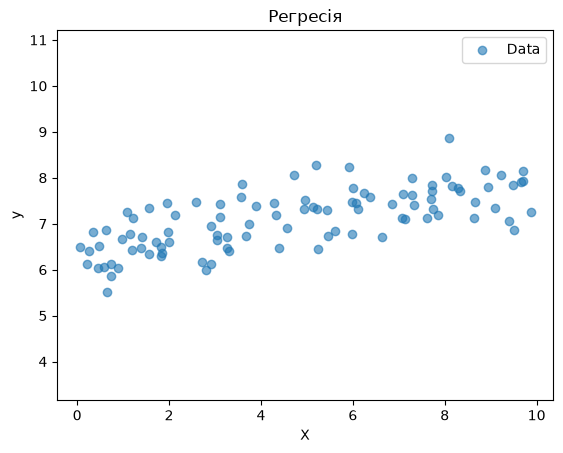

In [11]:
# Тестові дані для регресіі
# У прикладі Х буде мати тільки одну характеристику, тобто одну колонку
X, y = generate_noisy_regression_data_direct(n_samples=100, n_features=1, noise=0.5, random_state=42)
# X: [100, 1]
# y: [100]
# Візуалізуємо дані
plot_data(X, y)

## 🧮 Математична форма моделі лінійної регресії

### 📐 Узагальнена форма моделі

Модель машинного навчання описується рівнянням:
$$
y' = f(x)
$$
- **x** — вхідні дані
- **y'** — прогнозоване значення
- **f** — модель прогнозування

---

### 🔑 Лінійна регресія

Модель лінійної регресії — це функція прямої лінії:
$$
y = kx + b
$$
Наша мета — знайти оптимальні значення **k** та **b**, щоб модель найкраще описувала дані.

Замість **k** в лінійній регресії використовується **w**, відповідно до традиційної нотації:
$$
f(x) = wx + b
$$
$$
y' = wx + b
$$
- **(w, b)** — параметри моделі, для яких потрібно знайти оптимальні значення.

---

Це основи лінійної регресії: ми шукаємо оптимальні параметри моделі для того, щоб вона найкраще передбачала значення на основі вхідних даних.

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Регресія'}, xlabel='X', ylabel='y'>)

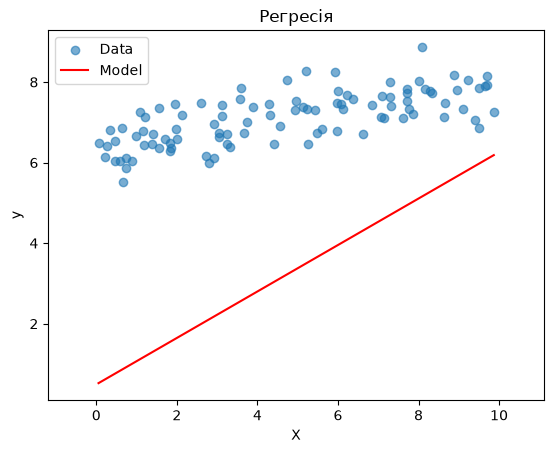

In [12]:
from sklearn.linear_model import LinearRegression

# Визначення моделі лінійноі регресіі
model = LinearRegression()

# Вручну виставити w, та b рандомними значеннями для візуалізаціі
model.coef_ = np.random.rand((1))       # w
model.intercept_ = np.random.rand((1))  # b

# візуалізувати модель
plot_model(X, y, model)

# З графіку, можно побачити, що така модель буде дуже поганою апроксимацією нашіх даних

# 🔍 Як знайти оптимальні значення для параметрів моделі та що робить функція `fit`?

---

### ⚡ Функція помилки

Щоб знайти найкращі значення параметрів моделі (w та b), нам потрібен критерій, який дозволить оцінити, наскільки добре модель працює. Функція помилки допомагає нам виміряти різницю між прогнозами моделі та фактичними значеннями.

**Функція помилки** — це критерій точності нашої моделі. Чим менше її значення, тим кращий прогноз.

#### Як це працює:
1. **Прогнозування**: Модель генерує прогнозоване значення.
2. **Порівняння**: Прогноз порівнюється з фактичним значенням.
3. **Розрахунок помилки**: Різниця між прогнозом і фактичним значенням є помилкою.
4. **Усереднення**: Функція помилки усереднює помилки для всіх спостережень.
5. **Оцінка**: Результат — числове значення "помилковості" моделі.

#### Мета функції помилки:
- **Навчання моделі**: Алгоритм намагається **мінімізувати** функцію помилки для досягнення кращої точності.
- **Порівняння моделей**: Функція помилки дозволяє порівнювати моделі та вибрати найкращу.

---

### 🧑‍🏫 Загальна форма функції помилки

$$
\left\{
    \begin{aligned}
         & y' = f(x) \quad - \text{модель машинного навчання} \\
         & loss = L(f(x), y) \quad - \text{функція помилки}
    \end{aligned}
\right.
$$

Функція помилки залежить від вхідних даних (x), даних-вчителя (y) та параметрів моделі (f).

---

### 📉 Функція помилки для регресії

Одна з найпоширеніших функцій помилки — **середня квадратична помилка** (СКП), або **mean squared error** (MSE), котра використовується в методі найменших квадратів (МНК). Він мінімізує усереднену суму квадратів різниць між фактичними значеннями та прогнозами моделі.

Рівняння МНК:
$$
MSE = \sum \frac{(y_i' - y_i)^2}{n}
$$
де:
- **y'** — прогнозовані значення,
- **y** — фактичні значення,
- **n** — кількість спостережень.

> 📌 Важливо: оскільки MSE враховує всі дані в наборі (X, y), ми можемо зафіксувати параметри та побудувати функцію МНК залежно від **w** і **b**.

---

### 🔧 Функція `fit`

Метод **`fit()`** в машинному навчанні використовується для **навчання моделі** на основі тренувального набору даних. Він оптимізує параметри моделі (наприклад, **w** та **b**) шляхом мінімізації функції помилки, використовуючи методи оптимізації (наприклад, градієнтний спуск).

- **Завдання**: знайти найкращі значення параметрів моделі.
- **Результат**: після навчання модель здатна робити точніші прогнози.

---

Цей процес допомагає створити модель, яка найкраще відповідає даним, мінімізуючи помилки та покращуючи прогнози.

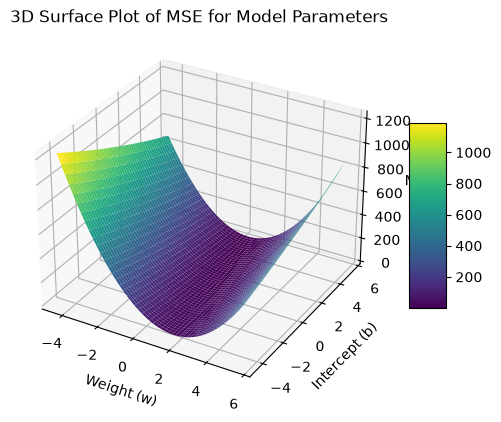

In [13]:
#@title Візуалізація МНК функціі помилки loss=MSE(w, b)

from sklearn.metrics import mean_squared_error
from mpl_toolkits.mplot3d import Axes3D  # ensure 3D toolkit is available

# Визначити допустимі значення для w та b
w_range = np.linspace(model.coef_[0] - 5, model.coef_[0] + 5, 50)
b_range = np.linspace(model.intercept_ - 5, model.intercept_ + 5, 50)
W, B = np.meshgrid(w_range, b_range)

# підрахувати МНК для кожноі комбінаціі
mse_grid = np.zeros_like(W)
for i in range(W.shape[0]):
    for j in range(W.shape[1]):
        y_pred = X * W[i, j] + B[i, j]
        mse_grid[i, j] = np.mean((y.flatten() - y_pred.flatten())**2)

# Create a 3D surface plot for MSE error with DARK_THEME background
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
# Set pane colors for 3D axes

surf = ax.plot_surface(W, B, mse_grid, cmap='viridis', edgecolor='none')

# Add axis titles with the light theme color for contrast
ax.set_xlabel('Weight (w)')
ax.set_ylabel('Intercept (b)')
ax.set_zlabel('MSE')
ax.set_title('3D Surface Plot of MSE for Model Parameters')

fig.colorbar(surf, shrink=0.5, aspect=5)

plt.show()

## 🔍 Знайдення оптимальних параметрів

Знаючи, як оцінити помилковість моделі, може здатися логічним, що ми можемо просто вирішити систему рівнянь регресії та МНК, прирівнявши помилку до 0:

$$
\left\{
    \begin{aligned}
         & \sum\frac{(y' - y)^2}{n} = 0 \\
         & y = wx + b \\
    \end{aligned}
\right.
$$

Але якщо підставити ці значення в рівняння, ми б отримали:

$$
\left\{
    \begin{aligned}
         & \sum\frac{(wx + b - y)^2}{n} = 0 \\
         & y = wx + b \\
    \end{aligned}
\right.
$$

Теоретично, ми могли б знайти значення **w** та **b** для ідеального прогнозу. Однак, ця система рівнянь **швидше за все не має рішення**. Щоб помилка дорівнювала 0, всі наші дані повинні ідеально лягати на пряму. Як ви можете побачити з графіка, це просто неможливо.

In [14]:
# Можемо подивитись яке мінімальне значення помилки змодельоване на нашему графіку
print('Мінімільний МНК на графіку:', mse_grid.min())

Мінімільний МНК на графіку: 0.4552830348821408


### 🧮 Аналітичний метод (використовуючи похідні)

Замість того щоб шукати оптимальні значення **w** та **b** в попередній системі рівнянь, ми можемо скористатися **властивістю похідних**.

#### 📐 Що дають похідні?

Похідна функції дозволяє дізнатися **кут нахилу** функції в певній точці або **швидкість змінювання** функції. Вона показує, як швидко змінюється значення функції щодо зміни її аргументу.
 

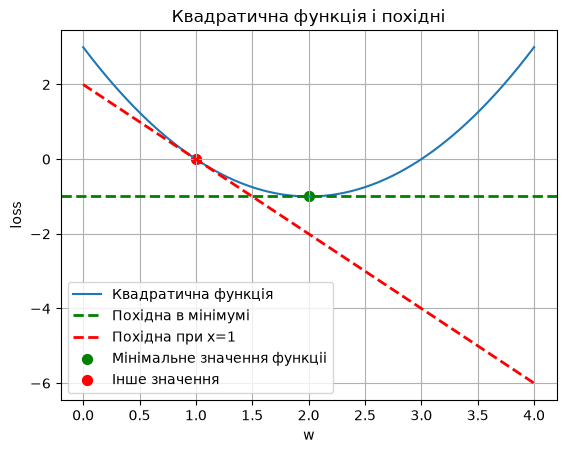

In [15]:
#@title Візуалізація похідной квадратичноі функціі

# Define the quadratic function
def quadratic_function(x):
    return x**2 - 4*x + 3

# Calculate the derivative of the quadratic function
def derivative_quadratic(x):
    return 2*x - 4

# Find the minimum point of the quadratic function (where the derivative is zero)
min_x = 2  # From the derivative 2x - 4 = 0, x = 2

# Calculate the derivative at the minimum point
derivative_at_min = derivative_quadratic(min_x)

# Choose another point for the derivative
other_x = 1  # Example point
derivative_at_other = derivative_quadratic(other_x)


# Generate x values for plotting
x_vals = np.linspace(0, 4, 400)
y_vals = quadratic_function(x_vals)


# Plot the quadratic function
plt.plot(x_vals, y_vals, label="Квадратична функція")

# Plot the tangent line at the minimum point (horizontal line)
plt.axhline(y=quadratic_function(min_x), xmin=0, xmax=1, color='green', linestyle='--', linewidth=2, label='Похідна в мінімумі')


# Plot the tangent line at another point
y_tangent_other = derivative_at_other * (x_vals - other_x) + quadratic_function(other_x)
plt.plot(x_vals, y_tangent_other, color='red', linestyle='--', linewidth=2, label='Похідна при x=1')


# Annotate the minimum point and the other point
plt.scatter(min_x, quadratic_function(min_x), color='green', s=50, label="Мінімальне значення функціі")
plt.scatter(other_x, quadratic_function(other_x), color='red', s=50, label='Інше значення')


# Add labels and title
plt.xlabel("w")
plt.ylabel("loss")
plt.title("Квадратична функція і похідні")
plt.legend()
plt.grid(True)

# Show the plot
plt.show()
 

(<Figure size 640x480 with 1 Axes>,
 <Axes: title={'center': 'Регресія'}, xlabel='X', ylabel='y'>)

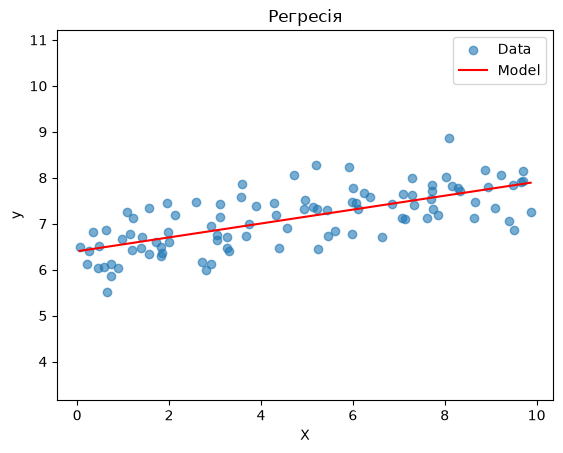

In [16]:
# для того щоб знайти оптимальні параметри, ми можемо викликати функцію fit
# класс LinearRegression розвʼязую вище описану систему рівнянь для отримання коефіцієнтів моделі
model.fit(X, y)

# візуалізуємо модель ще раз
plot_model(X, y, model)

# Тепер наша пряма, найліпшим образом проходить через дані.
# Звісно це не ідеальна модель, так как, ми бачимо, природа даних є нелінійною, тому що в них є певний разброс.

## 🏃‍♂️ Градієнтний спуск

Аналітичний метод працює добре для лінійної регресії, але має кілька суттєвих недоліків:

### ❗ Недоліки аналітичного методу:
- **Обчислювальна складність**: Для великих наборів даних і великої кількості характеристик рішення системи рівнянь може бути дуже ресурсоємним.
- **Чутливість до мультиколінеарності**: Якщо незалежні змінні сильно корелюють, рішення може бути нестабільним і давати помилкові результати.

### 🚀 Градієнтний спуск

Щоб подолати ці недоліки, застосовується **градієнтний спуск** — найпопулярніший метод оптимізації для нейронних мереж.

Градієнтний спуск — це **ітеративний алгоритм**, який допомагає знайти мінімум функції помилки.

### Як це працює:
1. **Початкові параметри**: Алгоритм починає з випадкових значень параметрів моделі.
2. **Обчислення градієнту**: Градієнт — це напрямок найшвидшого зростання функції помилки в поточній точці.
3. **Оновлення параметрів**: Параметри моделі оновлюються в напрямку, протилежному градієнту. Це допомагає зменшити помилку. Величина кроку визначається через **швидкість навчання** (learning rate).
4. **Повторення**: Алгоритм повторює ці кроки, поки не досягне мінімуму або не буде досягнуто критерію зупинки.

### 🧮 Математичне формулювання:

$$
loss = L(w, b)
$$

Обновлення параметрів:
$$
\left\{
    \begin{aligned}
         & w_i = w_{i-1} - \mu \nabla L(w) \quad - \text{градієнт функції помилки від } w \\
         & b_i = b_{i-1} - \mu \nabla L(b) \quad - \text{градієнт функції помилки від } b \\
         & \mu \quad - \text{швидкість навчання (learning rate)}
    \end{aligned}
\right.
$$

Градієнтний спуск дозволяє ефективно знаходити оптимальні параметри, мінімізуючи функцію помилки через ітерації.

In [17]:
# для того щоб оптимізувати лінійну регресію, за допомогою градієнтного спуску, використовується класс SGDRegressor
# SGDRegressor - Stochastic Gradient Descent Regressor, або регрессор стохастичного градієнтного спуску
# стохастичний означає, що помилка буде підраховуватись не як середня згідно по всьому датасету, а по одному рандомному запису

# max_iter - кількість ітерацій оптимізаціі
# eta0 - швидкість навчання
# learning_rate='constant' - швидкість буде константною протягом всього навчання
model = SGDRegressor(max_iter=100, eta0=0.01, learning_rate='constant')

# натренувати модель
model.fit(X, y)

,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",100
,"learning_rate learning_rate: str, default='invscaling'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where t0 is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': eta = eta0, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if early_stopping is True, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'constant'
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only if `loss` is'huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'.For 'huber', determines the threshold at which it becomes lessimportant to get the

## 📊 Лінійна регресія з багатьма характеристиками

Якщо наші дані мають більше однієї характеристики (тобто таблиця **X** має більше однієї колонки), лінійна регресія набуває наступного вигляду:

$$
y' = w_0x_0 + w_1x_1 + \dots + w_nx_n + b
$$

де:
- **$n$** — кількість характеристик (ознак), що використовуються для прогнозування.
- **$w_0, w_1, \dots, w_n$** — коефіцієнти для кожної характеристики.
- **$b$** — зміщення.

### 🧑‍💻 Як це виглядає на графіку:
- Для **n = 2** (дві характеристики) модель лінійної регресії буде виглядати як **площина** на графіку.
- Для **n > 2** (більше двох характеристик) модель перетворюється на **гіперплощину**, яку неможливо безпосередньо зобразити в 2D.

---

Цей підхід дозволяє враховувати кілька факторів одночасно для більш точного прогнозування, але вимагає додаткових обчислювальних ресурсів для вищих вимірів.

In [18]:
# Генерація даних з 2ма характеристиками
X, y = generate_noisy_regression_data_direct(n_samples=100, n_features=2, noise=0.5, random_state=42)
# X: [100, 2]
# y: [100]

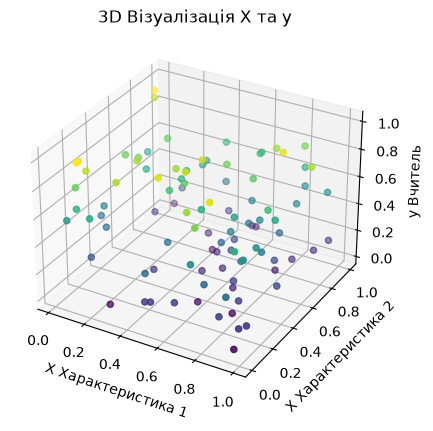

In [19]:
#@title Візуалізація даних з двома характеристиками

from mpl_toolkits.mplot3d import Axes3D

# Assuming you have X and y data as NumPy arrays
# Example data (replace with your actual data)
X = np.random.rand(100, 2)  # 100 samples, 2 features
y = np.random.rand(100)    # 100 target values


fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X[:, 0], X[:, 1], y, c=y, cmap='viridis')

ax.set_xlabel('X Характеристика 1')
ax.set_ylabel('X Характеристика 2')
ax.set_zlabel('y Вчитель')
ax.set_title('3D Візуалізація X та y')

plt.show()

In [ ]:
#@title Візуалізація площини лінійноі регресіі на графіку з данними

import pandas as pd
import matplotlib as mpl
import seaborn as sns
from matplotlib.animation import FuncAnimation
import random
from mpl_toolkits.mplot3d import Axes3D  # ensure 3D toolkit is available


#Visualization
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Scatter plot of the data points
ax.scatter(X[:, 0], X[:, 1], y, c=y, cmap='viridis', label='Data Points')


# Create a meshgrid for the plane
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1),
                     np.arange(y_min, y_max, 0.1))

# Predict the z values using the trained model
z = model.predict(np.c_[xx.ravel(), yy.ravel()])
z = z.reshape(xx.shape)


# Plot the plane
ax.plot_surface(xx, yy, z, alpha=0.5, cmap='viridis', label='Regression Plane')

# Customize the plot (labels, title, etc.)
ax.set_xlabel('X Характеристика 1')
ax.set_ylabel('X Характеристика 2')
ax.set_zlabel('y Вчитель')
ax.set_title('Площина регресіі разом із даними')
ax.legend() # Added legend

plt.show()